# 02b — ExpGrad `difference_bound` sweep (Zien Xu)
Resolves the "Open question" in the README's ExpGrad section. Selection rule and bounds were committed to the README on 23 Oct 2026 **before** any run (commit d20d955).

- Bounds: 0.001, 0.01, 0.05, 0.1 (`max_iter=40`). ~30 min each, ~2-2.5 h total.
- Per bound, on Drive: `preds/preds_expgrad_db<b>.parquet`, `models/expgrad_db<b>/` (components, weights + per-component `cut_`, `diag.json`). A bound is skipped on rerun if its `diag.json` exists, so a disconnect costs at most one fit.
- Reported: the full table + plot (trade-off curve). "The ExpGrad result" = val FPR ratio closest to 1.0 (pre-registered).
- The 23 Sep `preds_expgrad.parquet` is only read (repro check) until the gated final cell.

In [1]:
# %% 1. Setup
from google.colab import drive; drive.mount('/content/drive')
import sys; sys.path.append('/content/drive/MyDrive/CS3268_Project/src')   # same path as 02; confirm it exists
!pip install -q fairlearn
import os, json, time, shutil, numpy as np, pandas as pd
from sklearn.base import BaseEstimator, ClassifierMixin
from fairlearn.reductions import ExponentiatedGradient, FalsePositiveRateParity
from common import (load_split, features, threshold_at_fpr, save_preds,
                    train_model, BEST_PARAMS, SEED, LABEL, ROOT, PREDS)

tr, va, te = load_split("train"), load_split("val"), load_split("test")
Xtr, ytr, gtr = features(tr), tr[LABEL], tr["age_group"]
Xva, yva = features(va), va[LABEL]
Xte = features(te)
vt = pd.concat([va, te], ignore_index=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# %% 2. Estimator (identical to 02) + helpers
class FixedFPRXGB(BaseEstimator, ClassifierMixin):
    def __init__(self, fpr=0.05, params=None):
        self.fpr, self.params = fpr, params
    def fit(self, X, y, sample_weight=None):
        self.classes_ = np.array([0, 1])
        self.model_ = train_model(X, y, sample_weight=sample_weight, params=self.params or BEST_PARAMS)
        self.cut_ = threshold_at_fpr(self.model_.predict_proba(X)[:, 1], y, self.fpr)  # in-sample
        return self
    def score_(self, X):
        return self.model_.predict_proba(X)[:, 1]
    def predict(self, X):
        return (self.score_(X) >= self.cut_).astype(int)

def mixture_score(eg, w, X):
    s = np.zeros(len(X))
    for wi, p in zip(w, eg.predictors_):
        if wi > 1e-8:
            s += wi * p.score_(X)
    return s / w[w > 1e-8].sum()

def randomized_fpr(eg, X, y, g):
    """ExpGrad's own rule: predict 1 with prob pmf[:,1]. Per-group FPR = mean pmf over honest rows."""
    p1 = eg._pmf_predict(X)[:, 1]
    honest = np.asarray(y) == 0
    return pd.Series(p1[honest]).groupby(np.asarray(g)[honest]).mean()

def group_stats(p):
    """per-group FPR / recall for a preds frame"""
    f = p[p.y_true == 0].groupby("age_group").decision.mean()
    r = p[p.y_true == 1].groupby("age_group").decision.mean()
    return f, r

BOUNDS = [0.001, 0.01, 0.05, 0.1]
bdir = lambda b: f"{ROOT}/models/expgrad_db{b}"
bpath = lambda b: f"{PREDS}/preds_expgrad_db{b}.parquet"

In [3]:
# %% 3. Sweep (checkpointed: finished bounds are skipped)
for b in BOUNDS:
    d = bdir(b)
    if os.path.exists(f"{d}/diag.json") and os.path.exists(bpath(b)):
        print(f"bound={b}: already done, skipping"); continue
    print(f"\n=== difference_bound = {b} ===")
    t0 = time.time()
    eg = ExponentiatedGradient(estimator=FixedFPRXGB(fpr=0.05),
                               constraints=FalsePositiveRateParity(difference_bound=b), max_iter=40)
    eg.fit(Xtr, ytr, sensitive_features=gtr)
    w = np.asarray(eg.weights_, dtype=float)
    kept = [i for i, wi in enumerate(w) if wi > 1e-8]
    print(f"  fitted in {(time.time()-t0)/60:.1f} min; {len(eg.predictors_)} components, {len(kept)} non-zero")

    s_va, s_te = mixture_score(eg, w, Xva), mixture_score(eg, w, Xte)
    cut = threshold_at_fpr(s_va, yva, 0.05)
    save_preds(f"expgrad_db{b}", vt, np.concatenate([s_va, s_te]), cut)

    os.makedirs(d, exist_ok=True)
    for i in kept:
        eg.predictors_[i].model_.save_model(f"{d}/comp_{i}.json")
    pd.DataFrame({"component": kept, "weight": w[kept],
                  "cut": [eg.predictors_[i].cut_ for i in kept]}).to_csv(f"{d}/weights.csv", index=False)

    rt, rv = randomized_fpr(eg, Xtr, ytr, gtr), randomized_fpr(eg, Xva, yva, va["age_group"])
    diag = dict(bound=b, n_components=len(eg.predictors_), n_nonzero=len(kept), global_cut=cut,
                rand_fpr_train_0=rt.get(0), rand_fpr_train_1=rt.get(1),
                rand_fpr_val_0=rv.get(0), rand_fpr_val_1=rv.get(1))
    json.dump(diag, open(f"{d}/diag.json", "w"))   # written last = completion marker
    print("  randomized FPR (0 / 1) train:", round(rt.get(0), 4), round(rt.get(1), 4),
          " val:", round(rv.get(0), 4), round(rv.get(1), 4))
    del eg


=== difference_bound = 0.001 ===
  fitted in 10.9 min; 5 components, 2 non-zero
  randomized FPR (0 / 1) train: 0.0498 0.051  val: 0.0446 0.0376

=== difference_bound = 0.01 ===
  fitted in 10.7 min; 5 components, 2 non-zero
  randomized FPR (0 / 1) train: 0.0477 0.06  val: 0.0426 0.044

=== difference_bound = 0.05 ===
  fitted in 17.2 min; 7 components, 2 non-zero
  randomized FPR (0 / 1) train: 0.0384 0.1  val: 0.0353 0.0746

=== difference_bound = 0.1 ===
  fitted in 21.2 min; 6 components, 1 non-zero
  randomized FPR (0 / 1) train: 0.0325 0.1258  val: 0.0298 0.0965


In [4]:
# %% 4. Summary table = the trade-off curve (val AND test, per README)
rows = []
def row(name, p, extra=None):
    out = {}
    for sp, m in (("val", p.month == 5), ("test", p.month >= 6)):
        f, r = group_stats(p[m])
        out.update({f"{sp}_fpr_0": f[0], f"{sp}_fpr_1": f[1], f"{sp}_ratio": f.min() / f.max(),
                    f"{sp}_recall_0": r[0], f"{sp}_recall_1": r[1],
                    f"{sp}_recall": p[m & (p.y_true == 1)].decision.mean()})
    out["flagged_more"] = "50+" if out["val_fpr_1"] > out["val_fpr_0"] else "under50"
    return {"bound": name, **out, **(extra or {})}

for b in BOUNDS:
    diag = json.load(open(f"{bdir(b)}/diag.json"))
    rows.append(row(str(b), pd.read_parquet(bpath(b)),
                    {k: diag[k] for k in ("n_components", "n_nonzero", "rand_fpr_train_0", "rand_fpr_train_1",
                                          "rand_fpr_val_0", "rand_fpr_val_1")}))
rows.append(row("baseline", pd.read_parquet(f"{PREDS}/preds_baseline.parquet")))
res = pd.DataFrame(rows)
for s in ("train", "val"):
    res[f"rand_ratio_{s}"] = res[[f"rand_fpr_{s}_0", f"rand_fpr_{s}_1"]].min(axis=1) / res[[f"rand_fpr_{s}_0", f"rand_fpr_{s}_1"]].max(axis=1)
res.to_csv(f"{ROOT}/models/expgrad_sweep_summary.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
print(res.round(4).T)
print("\nDiagnostic: rand_ratio_train ~ 1 but val_ratio (deployed) far from 1  => decision-rule switch."
      "\n            rand_ratio_val ~ 1 as well => in-sample cut_ optimism is not the story; look elsewhere.")

                        0        1       2       3         4
bound               0.001     0.01    0.05     0.1  baseline
val_fpr_0          0.0594   0.0586  0.0422  0.0368    0.0368
val_fpr_1          0.0048   0.0083  0.0874  0.1135    0.1135
val_ratio          0.0806   0.1423  0.4831  0.3247    0.3247
val_recall_0       0.5547   0.5494  0.4888  0.4601    0.4601
val_recall_1       0.1723   0.2085  0.6681  0.7234    0.7234
val_recall         0.4274   0.4359  0.5485  0.5478    0.5478
test_fpr_0         0.0709   0.0708   0.051  0.0465    0.0465
test_fpr_1         0.0083   0.0132  0.1091  0.1431    0.1431
test_ratio         0.1165    0.187  0.4671  0.3249    0.3249
test_recall_0      0.6024   0.6003  0.5299  0.5109    0.5109
test_recall_1      0.1982   0.2649  0.6825  0.7391    0.7391
test_recall        0.4635   0.4851  0.5823  0.5893    0.5893
flagged_more      under50  under50     50+     50+       50+
n_components          5.0      5.0     7.0     6.0       NaN
n_nonzero             2.

In [5]:
# %% 5. Repro check: 0.01 refit vs the 23 Sep run (tolerance 0.5pp on val per-group FPR)
old_path = next((p for p in (f"{PREDS}/preds_expgrad_prelim_0923.parquet", f"{PREDS}/preds_expgrad.parquet")
                 if os.path.exists(p)), None)
if old_path:
    old = pd.read_parquet(old_path); old = old[old.month == 5]
    fo, _ = group_stats(old)
    new = res[res.bound == "0.01"].iloc[0]
    d = max(abs(fo[0] - new.val_fpr_0), abs(fo[1] - new.val_fpr_1))
    print(f"max |refit - 23 Sep| val FPR = {d:.4f}  ->", "OK" if d <= 0.005 else "MISMATCH: investigate before trusting the sweep")

max |refit - 23 Sep| val FPR = 0.0000  -> OK


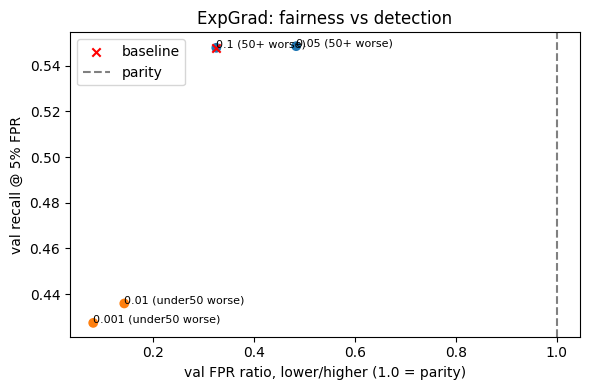

In [6]:
# %% 6. Plot: fairness ratio vs overall recall (val)
import matplotlib.pyplot as plt
sw, base = res[res.bound != "baseline"], res[res.bound == "baseline"].iloc[0]
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(sw.val_ratio, sw.val_recall, c=["C0" if m == "50+" else "C1" for m in sw.flagged_more])
for _, r in sw.iterrows():
    ax.annotate(f"{r.bound} ({r.flagged_more} worse)", (r.val_ratio, r.val_recall), fontsize=8)
ax.scatter([base.val_ratio], [base.val_recall], marker="x", c="red", label="baseline")
ax.axvline(1.0, ls="--", c="gray", label="parity")
ax.set_xlabel("val FPR ratio, lower/higher (1.0 = parity)"); ax.set_ylabel("val recall @ 5% FPR")
ax.set_title("ExpGrad: fairness vs detection"); ax.legend(); plt.tight_layout()
plt.savefig(f"{ROOT}/models/expgrad_tradeoff.png", dpi=150); plt.show()

In [7]:
# %% 7. Winner by the pre-registered rule (val FPR ratio closest to 1.0). Read-only.
sw = res[res.bound != "baseline"].copy()
winner = sw.loc[(sw.val_ratio - 1).abs().idxmin(), "bound"]
print("winner:", winner); print(sw.set_index("bound")[["val_ratio", "val_recall", "flagged_more"]].round(4))

winner: 0.05
       val_ratio  val_recall flagged_more
bound                                    
0.001     0.0806      0.4274      under50
0.01      0.1423      0.4359      under50
0.05      0.4831      0.5485          50+
0.1       0.3247      0.5478          50+


In [8]:
# %% 8. FINALIZE — set CONFIRM=True only after reading cells 4, 5, 7. Nothing is deleted.
CONFIRM = False
if CONFIRM:
    canon, prelim = f"{PREDS}/preds_expgrad.parquet", f"{PREDS}/preds_expgrad_prelim_0923.parquet"
    if os.path.exists(canon) and not os.path.exists(prelim):
        os.rename(canon, prelim)
    shutil.copyfile(bpath(winner), canon)
    cdir = f"{ROOT}/models/expgrad_components"
    if os.path.exists(cdir) and not os.path.exists(cdir + "_prelim_0923"):
        os.rename(cdir, cdir + "_prelim_0923")
    shutil.copytree(bdir(winner), cdir, dirs_exist_ok=True)
    shutil.copyfile(f"{bdir(winner)}/weights.csv", f"{ROOT}/models/expgrad_weights.csv")
    print("canonical ExpGrad =", winner, "(old files kept as *_prelim_0923)")